# Yassin: construction and collision severity
Run from the repository root in VS Code with the project `.venv` (Python 3.14.8); install `pip install -r requirements.txt`. Run All uses the committed integrated table, makes no API calls, and refreshes only Yassin's research assets. Exactly one chart answers each question.

Input: Issa's `phase2_data_integration_issa.ipynb` produces `data/zip_year.csv`. Full-year comparisons cover 2022–2025; 2026 covers January–October and appears only as a dashed continuation of the borough trend. These are associations, with no claim of a causal effect.

**Datasets used (NYC Open Data):** [DOB NOW: Build Job Application Filings (w9ak-ipjd)](https://data.cityofnewyork.us/d/w9ak-ipjd) and [Motor Vehicle Collisions, Crashes (h9gi-nx95)](https://data.cityofnewyork.us/d/h9gi-nx95).

In [1]:
from pathlib import Path
import hashlib
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

INPUT = Path("data/zip_year.csv")
ASSETS = Path("assets/rq")
FULL_YEARS = [2022, 2023, 2024, 2025]
YEARS = FULL_YEARS + [2026]
BOROUGHS = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
DRAWS, SEED = 2000, 20261109
COUNTS = ["new_building_count", "housing_job_count", "collision_count", "persons_killed",
          "pedestrians_killed", "cyclist_killed", "motorist_killed"]
REQUIRED = ["zip_code", "year", "borough", "low_data_flag", "is_partial_year"] + COUNTS

def load_table(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing. Run phase2_data_integration_issa.ipynb first.")
    table = pd.read_csv(path, dtype={"zip_code": "string"})
    missing = sorted(set(REQUIRED) - set(table.columns))
    if missing:
        raise ValueError(f"Missing required columns: {missing}. Tell Ahmed; do not invent replacements.")
    if table[REQUIRED].isna().any().any():
        raise ValueError("Missing values in required analysis columns.")
    if not table.zip_code.str.fullmatch(r"[0-9]{5}").all():
        raise ValueError("ZIP codes must be five-digit strings.")
    if table.duplicated(["zip_code", "year"]).any():
        raise ValueError("Duplicate ZIP-year keys.")
    for col in ["year"] + COUNTS:
        values = pd.to_numeric(table[col], errors="raise")
        if not np.isfinite(values).all() or (values < 0).any() or (values % 1 != 0).any():
            raise ValueError(f"{col} must contain nonnegative integers.")
        table[col] = values.astype("int64")
    for col in ["low_data_flag", "is_partial_year"]:
        mapped = table[col].astype("string").str.lower().map({"true": True, "false": False})
        if mapped.isna().any():
            raise ValueError(f"Invalid Boolean values in {col}.")
        table[col] = mapped.astype(bool)
    if not table.year.isin(YEARS).all() or set(table.year) != set(YEARS):
        raise ValueError("Expected only years 2022–2026, with every year represented.")
    if not table.is_partial_year.eq(table.year.eq(2026)).all():
        raise ValueError("Partial-year flags must identify exactly 2026.")
    if not table.borough.isin(BOROUGHS).all():
        raise ValueError("Unexpected borough; resolve upstream.")
    if (table.persons_killed > 0).where(table.collision_count.eq(0), False).any():
        raise ValueError("Fatalities reported with zero collisions.")
    return table

def pooled_bootstrap(zip_totals, draws=DRAWS, seed=SEED):
    """Paired numerators and denominators resampled together, one cluster per ZIP."""
    a = zip_totals[["collision_count", "persons_killed", "vulnerable_killed"]].to_numpy(dtype=float)
    if len(a) < 2 or a[:, 0].sum() <= 0:
        raise ValueError("Need multiple ZIPs and a positive pooled collision denominator.")
    indexes = np.random.default_rng(seed).integers(0, len(a), size=(draws, len(a)))
    sums = a[indexes].sum(axis=1)
    if (sums[:, 0] <= 0).any():
        raise ValueError("Bootstrap produced an empty collision denominator; inspect group support.")
    rates = 1000 * sums[:, 1:] / sums[:, :1]
    point = 1000 * a[:, 1:].sum(axis=0) / a[:, 0].sum()
    intervals = np.percentile(rates, [2.5, 97.5], axis=0)
    return point, intervals

def borough_gaps(table):
    totals = table.groupby(["year", "borough"])[["collision_count", "new_building_count"]].sum()
    expected = pd.MultiIndex.from_product([YEARS, BOROUGHS], names=["year", "borough"])
    totals = totals.reindex(expected)
    if totals.isna().any().any() or (totals.new_building_count <= 0).any():
        raise ValueError("Sparse/missing borough construction totals: discuss denominator with Ahmed.")
    city = totals.groupby(level="year").transform("sum")
    if (city <= 0).any().any():
        raise ValueError("Nonpositive citywide denominator.")
    totals["collision_share_pct"] = 100 * totals.collision_count / city.collision_count
    totals["construction_share_pct"] = 100 * totals.new_building_count / city.new_building_count
    totals["gap_pp"] = totals.collision_share_pct - totals.construction_share_pct
    return totals.reset_index()

source = load_table(INPUT)
eligible = source.loc[~source.low_data_flag].copy()
full = eligible.loc[eligible.year.isin(FULL_YEARS)].copy()
print("Input SHA256:", hashlib.sha256(INPUT.read_bytes()).hexdigest())
print(f"Input: {len(source):,} rows x {source.shape[1]} columns")
print(f"Excluded low_data_flag rows: {int(source.low_data_flag.sum()):,}; retained: {len(eligible):,}")
print("Retained rows by year:\n" + eligible.groupby("year").size().to_string())
print("Full-year rows per ZIP (coverage is not assumed balanced):\n" + full.groupby("zip_code").size().value_counts().sort_index().to_string())
print(f"Bootstrap draws: {DRAWS:,}; fixed seed: {SEED}")
print("Upstream limitation: about 28% of collisions lack usable ZIP codes; missingness is higher in 2022–2023.")
ASSETS.mkdir(parents=True, exist_ok=True)

Input SHA256: 5a60f6853f6c32c626a695639a10ecb4e744bb4db1e48a0614b02624a3a50465
Input: 1,123 rows x 25 columns
Excluded low_data_flag rows: 52; retained: 1,071
Retained rows by year:
year
2022    215
2023    215
2024    218
2025    211
2026    212
Full-year rows per ZIP (coverage is not assumed balanced):
1      2
2      4
3      7
4    207
Bootstrap draws: 2,000; fixed seed: 20261109
Upstream limitation: about 28% of collisions lack usable ZIP codes; missingness is higher in 2022–2023.


## Q1 — How deadly are the crashes in ZIP codes with a lot of new construction?
**Why it matters.** New Yorkers need to distinguish the severity of reported crashes from simply having more crashes in busy building areas.

**Method and rejected alternative.** Sum retained full-year records by ZIP, rank on total new buildings, and use the inclusive lower and upper quartile cutoffs. Keep ties together and print group sizes. Retained ZIP-year coverage may differ across ZIPs. Pool fatalities and collisions within each group; do not average small ZIP rates. Resample whole ZIPs, including all their retained years, with replacement for percentile bootstrap intervals. This retains within-ZIP clustering; it is descriptive uncertainty, not a randomized experiment. We reject injury-rate quartiles, which repeat Ahmed's analysis, and an unweighted mean of rare ZIP fatality rates.

**Chart.** Grouped bars show the two pooled fatality rates; error bars show uncertainty on the same deaths-per-collision scale. Printed totals and intervals support the finding below.

Construction cutoff totals per ZIP: lower <= 2; upper >= 42
          group                 metric  ZIPs  collisions  deaths     rate    lower    upper
Bottom quartile            All persons    58       10001      24 2.399760 1.298716 3.273788
Bottom quartile Pedestrians + cyclists    58       10001      15 1.499850 0.674472 2.299471
   Top quartile            All persons    56      101334     221 2.180907 1.929663 2.453920
   Top quartile Pedestrians + cyclists    56      101334     124 1.223676 1.029583 1.423406
95% intervals overlap (All persons): True
95% intervals overlap (Pedestrians + cyclists): True


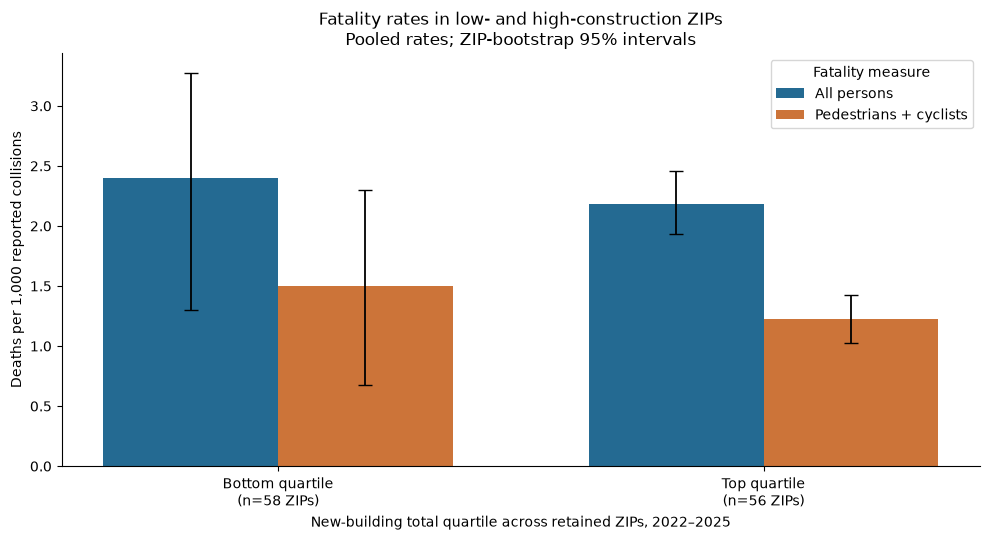

In [2]:
zip_totals = full.groupby("zip_code")[COUNTS].sum()
zip_totals["vulnerable_killed"] = zip_totals.pedestrians_killed + zip_totals.cyclist_killed
q25, q75 = zip_totals.new_building_count.quantile([0.25, 0.75])
assert q25 < q75, "Construction quartiles are not separable."
groups = {"Bottom quartile": zip_totals.loc[zip_totals.new_building_count.le(q25)],
          "Top quartile": zip_totals.loc[zip_totals.new_building_count.ge(q75)]}
rows = []
for group, values in groups.items():
    point, ci = pooled_bootstrap(values)
    for j, metric in enumerate(["All persons", "Pedestrians + cyclists"]):
        rows.append({"group": group, "metric": metric, "ZIPs": len(values),
                     "collisions": int(values.collision_count.sum()),
                     "deaths": int(values[["persons_killed", "vulnerable_killed"][j]].sum()),
                     "rate": point[j], "lower": ci[0, j], "upper": ci[1, j]})
q1 = pd.DataFrame(rows)
print(f"Construction cutoff totals per ZIP: lower <= {q25:g}; upper >= {q75:g}")
print(q1.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
overlap = {}
for metric in q1.metric.unique():
    v = q1.loc[q1.metric.eq(metric)]
    overlap[metric] = bool(v.lower.max() <= v.upper.min())
    print(f"95% intervals overlap ({metric}): {overlap[metric]}")
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(2)
for j, (metric, color) in enumerate(zip(q1.metric.unique(), ["#246a92", "#cc7439"])):
    v = q1.loc[q1.metric.eq(metric)].set_index("group").loc[list(groups)]
    yerr = np.vstack([v.rate - v.lower, v.upper - v.rate])
    assert (yerr >= 0).all(), "Percentile interval does not bracket estimate; use explicit endpoints."
    ax.bar(x + (j - 0.5) * .36, v.rate, width=.36, label=metric, color=color,
           yerr=yerr, capsize=5, error_kw={"elinewidth": 1.3})
ax.set(xticks=x, xticklabels=[f"{g}\n(n={len(v)} ZIPs)" for g, v in groups.items()],
       xlabel="New-building total quartile across retained ZIPs, 2022–2025",
       ylabel="Deaths per 1,000 reported collisions",
       title="Fatality rates in low- and high-construction ZIPs\nPooled rates; ZIP-bootstrap 95% intervals")
ax.legend(title="Fatality measure")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ASSETS / "yassin_q1.png", dpi=180)
plt.show()
plt.close(fig)

In [3]:
q1_parts = []
for metric in q1.metric.unique():
    v = q1.loc[q1.metric.eq(metric)].set_index("group")
    descriptions = []
    for group in groups:
        r = v.loc[group]
        descriptions.append(f"{group.lower()}: {r['rate']:.2f} deaths per 1,000 collisions "
                            f"(95% interval {r['lower']:.2f}–{r['upper']:.2f}; "
                            f"{int(r['deaths']):,} deaths / {int(r['collisions']):,} collisions)")
    q1_parts.append(f"{metric}: " + "; ".join(descriptions) +
                    f". The intervals {'overlap' if overlap[metric] else 'do not overlap'}.")
limitations = ("About 28% of upstream crashes have no usable ZIP and are excluded, especially in 2022–2023. "
              "There is no traffic or population exposure denominator; deaths per collision describe severity among "
              "reported crashes, not a resident's risk. ZIPs are not neighborhoods. Busy areas can have both more "
              "construction and traffic. Coverage, composition and reporting can confound these associations; "
              "interval overlap is not a formal test of a group difference.")
finding1 = " ".join(q1_parts) + " " + limitations
question1 = "How deadly are the crashes in ZIP codes with a lot of new construction?"
print(finding1)
(ASSETS / "yassin_q1.md").write_text(question1 + "\n\n" + finding1 + "\n", encoding="utf-8")
display(Markdown("**Finding and limitations.** " + finding1))

All persons: bottom quartile: 2.40 deaths per 1,000 collisions (95% interval 1.30–3.27; 24 deaths / 10,001 collisions); top quartile: 2.18 deaths per 1,000 collisions (95% interval 1.93–2.45; 221 deaths / 101,334 collisions). The intervals overlap. Pedestrians + cyclists: bottom quartile: 1.50 deaths per 1,000 collisions (95% interval 0.67–2.30; 15 deaths / 10,001 collisions); top quartile: 1.22 deaths per 1,000 collisions (95% interval 1.03–1.42; 124 deaths / 101,334 collisions). The intervals overlap. About 28% of upstream crashes have no usable ZIP and are excluded, especially in 2022–2023. There is no traffic or population exposure denominator; deaths per collision describe severity among reported crashes, not a resident's risk. ZIPs are not neighborhoods. Busy areas can have both more construction and traffic. Coverage, composition and reporting can confound these associations; interval overlap is not a formal test of a group difference.


**Finding and limitations.** All persons: bottom quartile: 2.40 deaths per 1,000 collisions (95% interval 1.30–3.27; 24 deaths / 10,001 collisions); top quartile: 2.18 deaths per 1,000 collisions (95% interval 1.93–2.45; 221 deaths / 101,334 collisions). The intervals overlap. Pedestrians + cyclists: bottom quartile: 1.50 deaths per 1,000 collisions (95% interval 0.67–2.30; 15 deaths / 10,001 collisions); top quartile: 1.22 deaths per 1,000 collisions (95% interval 1.03–1.42; 124 deaths / 101,334 collisions). The intervals overlap. About 28% of upstream crashes have no usable ZIP and are excluded, especially in 2022–2023. There is no traffic or population exposure denominator; deaths per collision describe severity among reported crashes, not a resident's risk. ZIPs are not neighborhoods. Busy areas can have both more construction and traffic. Coverage, composition and reporting can confound these associations; interval overlap is not a formal test of a group difference.

## Q2 — Which boroughs account for a larger share of collisions than of construction, and has that changed?
**Why it matters.** The borough distribution helps New Yorkers see whether construction and reported crash counts concentrate in the same places.

**Method and rejected alternative.** Within each year and after the same low-data exclusion, divide each borough's collisions and new buildings by their respective citywide totals over retained ZIPs. Subtract construction share from collision share in percentage points. Use new buildings because every borough-year has positive support, and print those totals; sparse ZIP counts do not require switching an aggregated borough denominator. We reject comparing raw borough counts, which hides different citywide totals, and reject treating partial-year totals as full-year changes. The partial-year shares describe January–October composition only and are not seasonally adjusted.

**Chart.** One line per borough shows the signed share gap over time; the final segment is dashed and labeled partial. Issa's merged question also examines borough share gaps, using housing jobs and a full-year heatmap. This requested analysis uses new buildings and a partial-year line continuation; it is related evidence, not an independent replication of a different question.

New buildings retained per borough-year (denominator support):
year           2022  2023  2024  2025  2026
borough                                    
Bronx           251   125   176   313   275
Brooklyn        474   339   284   441   383
Manhattan        75    31    48    73    71
Queens          617   522   473   614   478
Staten Island   530   884   277   319   364
Borough share calculations (% for shares, percentage points for gap):
 year       borough  collision_count  new_building_count  collision_share_pct  construction_share_pct     gap_pp
 2022         Bronx            12285                 251            17.874811               12.891628   4.983183
 2022      Brooklyn            23390                 474            34.032709               24.345146   9.687562
 2022     Manhattan            11941                  75            17.374287                3.852080  13.522207
 2022        Queens            18394                 617            26.763473               31.689779  -4.9

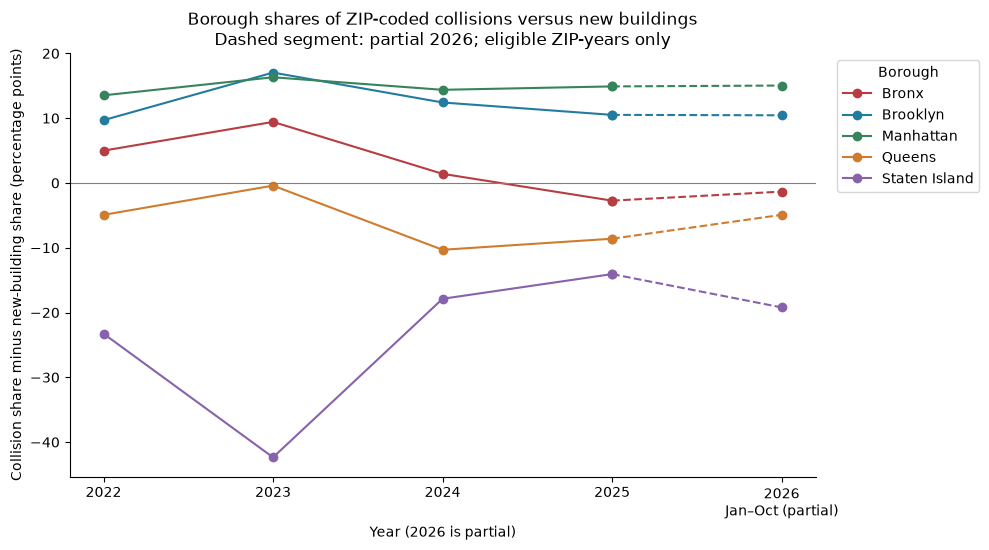

Mean full-year gap (percentage points):
borough
Staten Island   -24.392385
Queens           -6.066476
Bronx             3.270040
Brooklyn         12.411858
Manhattan        14.776963
Using new buildings, Manhattan has the largest mean positive gap in full years 2022–2025 (+14.78 percentage points), and Staten Island the largest negative gap (-24.39 points). Bronx: +4.98 points in 2022, -2.73 in 2025, -1.34 in partial January–October 2026. Brooklyn: +9.69 points in 2022, +10.51 in 2025, +10.44 in partial January–October 2026. Manhattan: +13.52 points in 2022, +14.90 in 2025, +15.03 in partial January–October 2026. Queens: -4.93 points in 2022, -8.61 in 2025, -4.92 in partial January–October 2026. Staten Island: -23.27 points in 2022, -14.07 in 2025, -19.21 in partial January–October 2026. Positive means a larger collision share; negative a larger new-building share. These are shares of retained ZIP-coded activity, not all city crashes, and 2026 is not directly comparable to a full year 

**Finding and limitations.** Using new buildings, Manhattan has the largest mean positive gap in full years 2022–2025 (+14.78 percentage points), and Staten Island the largest negative gap (-24.39 points). Bronx: +4.98 points in 2022, -2.73 in 2025, -1.34 in partial January–October 2026. Brooklyn: +9.69 points in 2022, +10.51 in 2025, +10.44 in partial January–October 2026. Manhattan: +13.52 points in 2022, +14.90 in 2025, +15.03 in partial January–October 2026. Queens: -4.93 points in 2022, -8.61 in 2025, -4.92 in partial January–October 2026. Staten Island: -23.27 points in 2022, -14.07 in 2025, -19.21 in partial January–October 2026. Positive means a larger collision share; negative a larger new-building share. These are shares of retained ZIP-coded activity, not all city crashes, and 2026 is not directly comparable to a full year because of seasonality. About 28% of upstream crashes have no usable ZIP and are excluded, especially in 2022–2023. There is no traffic or population exposure denominator; deaths per collision describe severity among reported crashes, not a resident's risk. ZIPs are not neighborhoods. Busy areas can have both more construction and traffic. Coverage, composition and reporting can confound these associations; interval overlap is not a formal test of a group difference.

In [4]:
q2 = borough_gaps(eligible)
print("New buildings retained per borough-year (denominator support):")
print(q2.pivot(index="borough", columns="year", values="new_building_count").to_string())
print("Borough share calculations (% for shares, percentage points for gap):")
print(q2.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
assert np.allclose(q2.groupby("year").collision_share_pct.sum(), 100)
assert np.allclose(q2.groupby("year").construction_share_pct.sum(), 100)
assert np.allclose(q2.groupby("year").gap_pp.sum(), 0)
fig, ax = plt.subplots(figsize=(10, 5.6))
for borough, color in zip(BOROUGHS, ["#b83d43", "#247ba0", "#36845b", "#cf7c2f", "#8862ab"]):
    v = q2.loc[q2.borough.eq(borough)].set_index("year").loc[YEARS]
    ax.plot(FULL_YEARS, v.loc[FULL_YEARS, "gap_pp"], marker="o", color=color, label=borough)
    ax.plot([2025, 2026], v.loc[[2025, 2026], "gap_pp"], marker="o", linestyle="--", color=color)
ax.axhline(0, color="gray", linewidth=.8)
ax.set(xticks=YEARS, xticklabels=["2022", "2023", "2024", "2025", "2026\nJan–Oct (partial)"],
       xlabel="Year (2026 is partial)", ylabel="Collision share minus new-building share (percentage points)",
       title="Borough shares of ZIP-coded collisions versus new buildings\nDashed segment: partial 2026; eligible ZIP-years only")
ax.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ASSETS / "yassin_q2.png", dpi=180)
plt.show()
plt.close(fig)
mean_gap = q2.loc[q2.year.isin(FULL_YEARS)].groupby("borough").gap_pp.mean().sort_values()
print("Mean full-year gap (percentage points):\n" + mean_gap.to_string(float_format=lambda v: f"{v:.6f}"))
most_negative, most_positive = mean_gap.index[0], mean_gap.index[-1]
finding2 = (f"Using new buildings, {most_positive} has the largest mean positive gap in full years "
            f"2022–2025 ({mean_gap.iloc[-1]:+.2f} percentage points), and {most_negative} the largest "
            f"negative gap ({mean_gap.iloc[0]:+.2f} points). ")
for borough in BOROUGHS:
    v = q2.loc[q2.borough.eq(borough)].set_index("year").gap_pp
    finding2 += (f"{borough}: {v[2022]:+.2f} points in 2022, {v[2025]:+.2f} in 2025, "
                 f"{v[2026]:+.2f} in partial January–October 2026. ")
finding2 += ("Positive means a larger collision share; negative a larger new-building share. "
             "These are shares of retained ZIP-coded activity, not all city crashes, and 2026 is not "
             "directly comparable to a full year because of seasonality. " + limitations)
question2 = "Which boroughs account for a larger share of collisions than of construction, and has that changed?"
print(finding2)
(ASSETS / "yassin_q2.md").write_text(question2 + "\n\n" + finding2 + "\n", encoding="utf-8")
display(Markdown("**Finding and limitations.** " + finding2))

## Reproducibility checks
Controlled checks verify the bootstrap's paired ZIP resampling, deterministic output, input failures, and share arithmetic. They do not download source records or change the integrated table.

In [5]:
# An equal rate in every ZIP must give a degenerate interval at that rate.
toy = pd.DataFrame({"collision_count": [100, 200, 300], "persons_killed": [1, 2, 3],
                    "vulnerable_killed": [0, 0, 0]})
p, ci = pooled_bootstrap(toy)
assert np.allclose(p, [10, 0]) and np.allclose(ci, [[10, 0], [10, 0]])
real = next(iter(groups.values()))
a, b = pooled_bootstrap(real)
a2, b2 = pooled_bootstrap(real)
assert np.array_equal(a, a2) and np.array_equal(b, b2)
assert np.allclose(a, 1000 * real[["persons_killed", "vulnerable_killed"]].sum() / real.collision_count.sum())
with tempfile.TemporaryDirectory() as directory:
    temp = Path(directory) / "table.csv"
    def must_fail(frame, text):
        frame.to_csv(temp, index=False)
        try:
            load_table(temp)
        except ValueError as error:
            assert text in str(error), str(error)
        else:
            raise AssertionError("Invalid input was accepted.")
    source.to_csv(temp, index=False)
    pd.testing.assert_frame_equal(load_table(temp), source)
    must_fail(source.drop(columns="cyclist_killed"), "Tell Ahmed")
    must_fail(pd.concat([source, source.iloc[:1]], ignore_index=True), "Duplicate")
    bad = source.copy(); bad.loc[0, "zip_code"] = "1234"; must_fail(bad, "five-digit")
    bad = source.copy(); bad["low_data_flag"] = bad.low_data_flag.astype("string")
    bad.loc[0, "low_data_flag"] = "maybe"; must_fail(bad, "Invalid Boolean")
    bad = source.copy(); bad.loc[0, "persons_killed"] = -1; must_fail(bad, "nonnegative")
    try:
        load_table(Path(directory) / "missing.csv")
    except FileNotFoundError as error:
        assert "phase2_data_integration_issa.ipynb" in str(error)
    else:
        raise AssertionError("Missing input was accepted.")
for number, question in [(1, question1), (2, question2)]:
    image = plt.imread(ASSETS / f"yassin_q{number}.png")
    assert image.ndim == 3 and image.shape[0] > 500 and image.std() > .05
    assert (ASSETS / f"yassin_q{number}.md").read_text(encoding="utf-8").splitlines()[0] == question
print("PASS: input round-trip, six rejected-input cases, paired pooled bootstrap, fixed-seed repeatability, share sums, two readable PNGs and website findings.")
print("Input still SHA256:", hashlib.sha256(INPUT.read_bytes()).hexdigest())

PASS: input round-trip, six rejected-input cases, paired pooled bootstrap, fixed-seed repeatability, share sums, two readable PNGs and website findings.
Input still SHA256: 5a60f6853f6c32c626a695639a10ecb4e744bb4db1e48a0614b02624a3a50465


## Contribution note
Yassin authored the initial collision cleaning (`phase1_collisions_initial_cleaning_yassin.ipynb`), the collision ZIP × year aggregation (`phase2_collisions_aggregation_yassin.ipynb`), and these two research analyses. Issa supplied the integrated table; upstream source cleaning and housing work retain their original ownership.

## Prompts used
The original task is appended to `AI_PROMPTS.txt` under Yassin, Phase 3 research questions. AI assisted the input checks, pooled ZIP bootstrap, borough-share calculations, chart code, generated findings, and reproducibility checks. All reported findings are generated from the printed calculations above and were checked by executing this notebook.